# EuroSAT Land-Cover Classification — A Comparative Deep Learning Study with Transfer Learning

# Notebook 04 — CNN Experiments

## 1. Objective

Notebook 03 trained a simple three-block CNN from scratch as the project's baseline (684,490 parameters, best validation accuracy 88.00%, best validation loss 0.3607 at Epoch 10, with overfitting appearing after that point).

This notebook studies how the following nine experiments affect validation accuracy, validation loss, and overfitting, relative to that baseline:

1. Data Augmentation
2. Batch Normalization
3. Dropout
4. Extra convolutional block (deeper)
5. Extra dense layer (larger classifier)
6. Global Average Pooling instead of Flatten
7. Wider convolutional blocks
8. Augmentation + BatchNorm + Dropout combined
9. A second run of the combined regularization configuration (Experiment 8) to examine run-to-run variability

The baseline itself is **not retrained** here — its Notebook 03 results are used as a fixed reference point.

## 2. Experimental Design

To keep the 9 experiments genuinely comparable, all of them share:

- The same manifest, stratified 80/10/10 split, and `tf.data` pipeline (recreated below, identically to Notebook 02, with `SEED = 42`) — this notebook is standalone and does not depend on runtime state from earlier notebooks.
- The same training configuration: Adam, `sparse_categorical_crossentropy`, `accuracy`, up to `EPOCHS = 15`, and the same `EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)`.
- The same evaluation rule: only `train_ds` and `val_ds` are used. **No `test_ds` is built or used anywhere in this notebook** — the test set stays reserved for Notebook 08.

Only one thing changes per experiment, with two exceptions: Experiment 8 combines three of the earlier changes (augmentation, BatchNorm, Dropout), and **Experiment 9 — Combined Regularization Re-run** repeats Experiment 8's exact architecture in a second run to observe run-to-run variability. Experiments 8 and 9 use the same architecture; Experiment 9 is not a new model architecture and is not being declared the final or best CNN. A single helper function (`compile_and_train`) trains every new experiment identically and records its results, so the training code isn't repeated nine times — the part that actually differs between experiments is each model's architecture, which is still written out in full below.

## 3. Imports

In [1]:
from pathlib import Path
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split

## 4. Configuration / Seeds

Seed 42 is set for Python, NumPy, and TensorFlow, and `set_seeds()` is called before each experiment. Fully deterministic execution is not enforced in this environment, so repeating a run may give somewhat different numbers; the results below are the results of the recorded runs. Notebook 04 does not use the test set.

In [ ]:
DATASET_ROOT = Path("data/EuroSAT_RGB")

CLASS_NAMES = [
    "AnnualCrop", "Forest", "HerbaceousVegetation",
    "Highway", "Industrial", "Pasture",
    "PermanentCrop", "Residential", "River",
    "SeaLake",
]

CLASS_TO_ID = {class_name: idx for idx, class_name in enumerate(CLASS_NAMES)}
EXPECTED_EXTENSIONS = {".jpg", ".jpeg"}

SEED = 42
IMAGE_SIZE = (64, 64)
NUM_CLASSES = 10
BATCH_SIZE = 32
EPOCHS = 15

def set_seeds(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seeds(SEED)

## 5. Recreate the Data Split & Pipeline (Notebook 02)

Same manifest, same two-stage stratified split, same `tf.data` pipeline as Notebook 02 — identical config and `SEED = 42`, so `train_ds` and `val_ds` match exactly. As in Notebook 03, a `test_ds` is deliberately never built in this notebook.

In [ ]:
records = []
for class_name in CLASS_NAMES:
    class_dir = DATASET_ROOT / class_name
    for path in class_dir.iterdir():
        if path.is_file() and path.suffix.lower() in EXPECTED_EXTENSIONS:
            records.append((str(path), class_name, CLASS_TO_ID[class_name]))

manifest_df = pd.DataFrame(records, columns=["filepath", "class_name", "label"])

train_df, temp_df = train_test_split(
    manifest_df, test_size=0.20, stratify=manifest_df["label"], random_state=SEED,
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED,
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print(f"Train:      {len(train_df)}")
print(f"Validation: {len(val_df)}")
print(f"(Test set:  {len(test_df)} — not loaded into a tf.data.Dataset in this notebook)")


def load_image(filepath, label):
    #Read a JPEG file, decode it, resize to IMAGE_SIZE, and scale pixels to [0, 1]
    image = tf.io.read_file(filepath)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label


def make_dataset(df, shuffle, seed=SEED, batch_size=BATCH_SIZE):
    filepaths = df["filepath"].values
    labels = df["label"].values

    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(df), seed=seed, reshuffle_each_iteration=True)

    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df, shuffle=False)

print("train_ds:", train_ds)
print("val_ds:  ", val_ds)

Train:      21600
Validation: 2700
(Test set:  2700 — not loaded into a tf.data.Dataset in this notebook)
train_ds: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>
val_ds:   <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>


## 6. Shared Training Helper

`compile_and_train` compiles a model with the shared training configuration, trains it on `train_ds` / `val_ds` with the shared `EarlyStopping` callback, times the run, reads off the best epoch (lowest `val_loss`), and appends one row to the shared `results` list. This is the only piece of logic reused across experiments — each experiment's architecture is still defined explicitly, in full, in its own cell.

**Reporting note:** `EarlyStopping` monitors validation *loss*, so the weights it restores correspond to the epoch with the lowest `val_loss` — which is not necessarily the epoch with the highest `val_accuracy`. The helper therefore records both, each with its own epoch, as separate columns: "Best Val Accuracy" is the maximum recorded validation accuracy across epochs, and "Best Val Loss" is the minimum recorded validation loss. The one-line summary printed under each experiment and the Results Comparison table in Section 17 both come from these same recorded values. (An earlier version of the helper reported "Best Val Accuracy" as the accuracy at the best-loss epoch; the outputs stored in this notebook come from the corrected helper.)


In [ ]:
results = []

def compile_and_train(model, name, main_change, epochs=EPOCHS):
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
    )

    start_time = time.time()
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        callbacks=[early_stopping],
        # train_ds is already shuffled by the pipeline (Section 5); shuffle=False here just
        # silences Keras's default shuffle=True warning for tf.data.Dataset inputs and changes
        # nothing about how the data is actually fed to the model.
        shuffle=False,
        verbose=2,
    )
    training_time_s = round(time.time() - start_time, 1)

    history_df = pd.DataFrame(history.history)
    history_df.index = history_df.index + 1
    history_df.index.name = "epoch"

    # Best validation LOSS  what EarlyStopping actually monitors and restores.
    best_val_loss_epoch = int(history_df["val_loss"].idxmin())
    best_val_loss = float(history_df["val_loss"].min())

    # Best validation ACCURACY  the true maximum, not necessarily the same epoch as above.
    best_val_acc_epoch = int(history_df["val_accuracy"].idxmax())
    best_val_acc = float(history_df["val_accuracy"].max())

    results.append({
        "Experiment": name,
        "Main Change": main_change,
        "Parameters": model.count_params(),
        "Best Val Accuracy": best_val_acc,
        "Best Val Accuracy Epoch": best_val_acc_epoch,
        "Best Val Loss": best_val_loss,
        "Best Val Loss Epoch": best_val_loss_epoch,
        "Training Time (s)": training_time_s,
    })

    print(f"\n{name}: best val_accuracy={best_val_acc:.2%} (epoch {best_val_acc_epoch}), "
          f"best val_loss={best_val_loss:.4f} (epoch {best_val_loss_epoch}), "
          f"params={model.count_params():,}, time={training_time_s}s")

    return history_df

## 7. Baseline Reference

The baseline is **not retrained** in this notebook. Its architecture and results are taken directly from Notebook 03 and recorded here as a fixed reference point so every experiment below can be compared against it.

**Why a baseline is needed:** without a simple, honest reference number, "improvement" has nothing to be measured against. **What it allows us to compare:** every technique below can be judged by how it moves validation accuracy, validation loss, and overfitting relative to this same number. **Why we don't retrain it here:** retraining would waste time reproducing a result we already have, and could introduce small run-to-run differences that would muddy the comparison — Notebook 03's actual executed result is the one that counts.

Baseline architecture (3 conv blocks: 32 → 64 → 128, `Flatten`, `Dense(128)`, `Dense(10, softmax)`):
- Parameters: **684,490**
- Best validation accuracy: **88.00%**
- Best validation loss: **0.3607**
- Best epoch: **10**
- Epoch budget: Notebook 03 configured the baseline with a maximum of 50 epochs, and `EarlyStopping` stopped it early at epoch 15. The experiments below were configured with a smaller maximum of `EPOCHS = 15`.
- Behavior: validation performance peaked around Epoch 10; training continued improving afterward while validation became less stable — increasing overfitting past that point.

In [ ]:
results.append({
    "Experiment": "Baseline Reference (Notebook 03)",
    "Main Change": "3 conv blocks (32-64-128) + Dense(128) - not retrained here",
    "Parameters": 684_490,
    "Best Val Accuracy": 0.8800,
    "Best Val Accuracy Epoch": 10,
    "Best Val Loss": 0.3607,
    "Best Val Loss Epoch": 10,
    "Training Time (s)": "N/A (not retrained)",
})

print("Baseline reference recorded (from Notebook 03, not retrained)")

Baseline reference recorded (from Notebook 03, not retrained).


## 8. Experiment 1 — Data Augmentation

**Question:** Does training-time image augmentation improve generalization?

**What changed?** `RandomFlip`, `RandomRotation`, and `RandomZoom` layers are added at the start of the baseline architecture; everything else (three conv blocks, `Flatten`, `Dense(128)`) is unchanged.
**Why test it?** Augmentation exposes the model to more variation of the same training images (flipped, slightly rotated, slightly zoomed), which can reduce overfitting to exact pixel patterns.
**What happens if we skip it?** The model only ever sees the original 21,600 training images in their original orientation, which is exactly the baseline.

Keras preprocessing layers like `RandomFlip`/`RandomRotation`/`RandomZoom` are only active during training (`model.fit`) and automatically turn into no-ops during validation/inference (`model.evaluate`/`predict`) — so `val_ds` still sees clean, unaugmented images, as required.

In [6]:
set_seeds()

model_aug = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64, 64, 3)),
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"),
], name="exp1_augmentation")

hist_aug = compile_and_train(
    model_aug, "Exp 1 - Data Augmentation", "RandomFlip + RandomRotation(0.1) + RandomZoom(0.1) added"
)

Epoch 1/15
675/675 - 47s - 70ms/step - accuracy: 0.4599 - loss: 1.3696 - val_accuracy: 0.6611 - val_loss: 0.9467
Epoch 2/15
675/675 - 51s - 76ms/step - accuracy: 0.6754 - loss: 0.8787 - val_accuracy: 0.7115 - val_loss: 0.7979
Epoch 3/15
675/675 - 49s - 72ms/step - accuracy: 0.7325 - loss: 0.7302 - val_accuracy: 0.7578 - val_loss: 0.6503
Epoch 4/15
675/675 - 50s - 74ms/step - accuracy: 0.7544 - loss: 0.6665 - val_accuracy: 0.7633 - val_loss: 0.6547
Epoch 5/15
675/675 - 89s - 132ms/step - accuracy: 0.7770 - loss: 0.6168 - val_accuracy: 0.7607 - val_loss: 0.6937
Epoch 6/15
675/675 - 50s - 74ms/step - accuracy: 0.7899 - loss: 0.5773 - val_accuracy: 0.7211 - val_loss: 0.8307
Epoch 7/15
675/675 - 54s - 80ms/step - accuracy: 0.8085 - loss: 0.5349 - val_accuracy: 0.8378 - val_loss: 0.4513
Epoch 8/15
675/675 - 54s - 80ms/step - accuracy: 0.8198 - loss: 0.4999 - val_accuracy: 0.8078 - val_loss: 0.5421
Epoch 9/15
675/675 - 61s - 90ms/step - accuracy: 0.8327 - loss: 0.4675 - val_accuracy: 0.7574 -

**Interpretation:** Augmentation did not improve validation performance in this run. Maximum validation accuracy was 83.78% (Epoch 7) and minimum validation loss 0.4513 (Epoch 7), compared with the baseline's 88.00% / 0.3607 — 4.22 percentage points lower in accuracy and a higher loss. `EarlyStopping` stopped the run at Epoch 12 (best-loss epoch 7 + patience 5). The training/validation gap was smaller than the baseline's: at Epoch 12 training accuracy was 86.35% against 82.81% validation (3.54 points), whereas the baseline had reached 93.43% training accuracy by Epoch 12. Training accuracy also rose more slowly, so augmentation reduced the visible overfitting signal without producing a better validation result here. Validation accuracy was noisy from epoch to epoch (72.11% at Epoch 6, 83.78% at Epoch 7, 75.74% at Epoch 9). A possible reason is that these augmentation settings slow learning for this small model within the available epochs, but this notebook does not test that.

## 9. Experiment 2 — Batch Normalization

**Question:** What is the effect of Batch Normalization on CNN training?

**What changed?** Each `Conv2D` now has `activation=None`, followed by `BatchNormalization()`, then a separate `ReLU()` — everything else matches the baseline.
**Why test it?** BatchNorm normalizes each layer's activations during training, which generally stabilizes and speeds up training and can act as a mild regularizer.
**What happens if we skip it?** That's exactly the baseline — activations aren't normalized between layers, which is fine but can make training slightly less stable, especially at higher learning rates.

In [7]:
set_seeds()

model_bn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64, 64, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation=None),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation=None),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation=None),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"),
], name="exp2_batchnorm")

hist_bn = compile_and_train(
    model_bn, "Exp 2 - Batch Normalization", "BatchNormalization after each Conv2D, before ReLU"
)

Epoch 1/15
675/675 - 94s - 139ms/step - accuracy: 0.6775 - loss: 0.9288 - val_accuracy: 0.6259 - val_loss: 1.0893
Epoch 2/15
675/675 - 71s - 105ms/step - accuracy: 0.7915 - loss: 0.6024 - val_accuracy: 0.6093 - val_loss: 1.2225
Epoch 3/15
675/675 - 73s - 108ms/step - accuracy: 0.8250 - loss: 0.5002 - val_accuracy: 0.7341 - val_loss: 0.8036
Epoch 4/15
675/675 - 79s - 116ms/step - accuracy: 0.8536 - loss: 0.4225 - val_accuracy: 0.6607 - val_loss: 0.9232
Epoch 5/15
675/675 - 71s - 105ms/step - accuracy: 0.8756 - loss: 0.3529 - val_accuracy: 0.7074 - val_loss: 0.9288
Epoch 6/15
675/675 - 78s - 115ms/step - accuracy: 0.8909 - loss: 0.3056 - val_accuracy: 0.7393 - val_loss: 0.8702
Epoch 7/15
675/675 - 97s - 143ms/step - accuracy: 0.9077 - loss: 0.2630 - val_accuracy: 0.7330 - val_loss: 0.8182
Epoch 8/15
675/675 - 71s - 105ms/step - accuracy: 0.9175 - loss: 0.2374 - val_accuracy: 0.7378 - val_loss: 1.1228

Exp 2 - Batch Normalization: best val_accuracy=73.93% (epoch 6), best val_loss=0.8036 (

**Interpretation:** Batch Normalization did not improve validation performance in this run. Maximum validation accuracy was **73.93% at Epoch 6**, and minimum validation loss was **0.8036 at Epoch 3** (where validation accuracy was 73.41%) — the two best epochs differ, and both are far below the baseline's 88.00% / 0.3607. Training accuracy rose faster than the baseline's (67.75% at Epoch 1 vs 54.50%, and 91.75% by Epoch 8), but validation did not follow: validation accuracy stayed between 60.93% and 73.93%, and validation loss moved erratically (1.2225 at Epoch 2, 0.8036 at Epoch 3, 1.1228 at Epoch 8). By Epoch 8 the training/validation accuracy gap was 17.97 points (91.75% vs 73.78%). `EarlyStopping` stopped the run at Epoch 8 (best-loss epoch 3 + patience 5). This does not show that Batch Normalization is generally harmful; it shows that this implementation, in this single run, did not generalize to the validation set well. The other two experiments that include BatchNorm (Experiments 8 and 9) also showed unstable validation curves, but this notebook does not isolate BatchNorm as the cause.

## 10. Experiment 3 — Dropout

**Question:** Can Dropout reduce overfitting?

**What changed?** A `Dropout(0.5)` layer is added between the two Dense layers in the classifier; the convolutional feature extractor is unchanged from the baseline.
**Why test it?** Dropout randomly zeroes out half the classifier's units on each training step, preventing the dense layer from co-adapting too closely to specific training examples. It's placed in the classifier (not the conv blocks) because that's where the baseline showed overfitting first — the final decision-making layers.
**What happens if we skip it?** That's the baseline — the classifier can rely on every unit every time, which makes it easier to overfit.

In [8]:
set_seeds()

model_dropout = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64, 64, 3)),
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"),
], name="exp3_dropout")

hist_dropout = compile_and_train(
    model_dropout, "Exp 3 - Dropout", "Dropout(0.5) added between the two Dense layers"
)

Epoch 1/15
675/675 - 54s - 80ms/step - accuracy: 0.4572 - loss: 1.4124 - val_accuracy: 0.6100 - val_loss: 1.0870
Epoch 2/15
675/675 - 47s - 70ms/step - accuracy: 0.6512 - loss: 0.9750 - val_accuracy: 0.7200 - val_loss: 0.7686
Epoch 3/15
675/675 - 56s - 83ms/step - accuracy: 0.7196 - loss: 0.7996 - val_accuracy: 0.7570 - val_loss: 0.7059
Epoch 4/15
675/675 - 41s - 61ms/step - accuracy: 0.7478 - loss: 0.7231 - val_accuracy: 0.7981 - val_loss: 0.5628
Epoch 5/15
675/675 - 42s - 62ms/step - accuracy: 0.7813 - loss: 0.6286 - val_accuracy: 0.7630 - val_loss: 0.6665
Epoch 6/15
675/675 - 42s - 62ms/step - accuracy: 0.8044 - loss: 0.5711 - val_accuracy: 0.8356 - val_loss: 0.4659
Epoch 7/15
675/675 - 43s - 63ms/step - accuracy: 0.8258 - loss: 0.5092 - val_accuracy: 0.8530 - val_loss: 0.4112
Epoch 8/15
675/675 - 57s - 85ms/step - accuracy: 0.8408 - loss: 0.4624 - val_accuracy: 0.8519 - val_loss: 0.4060
Epoch 9/15
675/675 - 55s - 82ms/step - accuracy: 0.8604 - loss: 0.4109 - val_accuracy: 0.8800 - 

**Interpretation:** Dropout achieved the highest maximum validation accuracy recorded in these experiments (88.96% at Epoch 15). However, because `EarlyStopping` monitored validation loss, the restored weights correspond to the best validation-loss epoch (Epoch 12, loss 0.3327), where validation accuracy was 88.59%. Compared with the baseline's 88.00% / 0.3607, the recorded maximum accuracy is 0.96 points higher and the minimum loss is 0.0280 lower. The overfitting signal was weaker than the baseline's: at Epoch 15 training accuracy was 92.23% against 88.96% validation (3.27 points), compared with a 13-point gap for the baseline at Epoch 15. Validation loss reached its minimum at Epoch 12 and then moved around (0.4131, 0.4082, 0.3656 at Epochs 13–15). Two caveats apply. First, this run used all 15 allowed epochs and its best validation accuracy occurred at the last allowed epoch, so it does not show whether more training would have helped or hurt. Second, the improvement over the baseline is modest (0.96 points is about 26 of the 2,700 validation images, and the Epoch 12 accuracy is 0.59 points above the baseline) and comes from one run, so it should be read as a possible small improvement rather than an established one.

## 11. Experiment 4 — Extra Convolutional Block (Deeper)

**Question:** Does increasing CNN depth improve feature extraction?

**What changed?** A fourth conv block is added: `32 → 64 → 128 → 256` filters (four `Conv2D` + `MaxPooling2D` pairs instead of three); classifier unchanged.
**Why test it?** Network **depth** (number of stacked layers) lets a CNN build increasingly abstract, hierarchical features — early layers learn edges/textures, later layers can combine those into more complex shapes.
**What happens if we skip it?** That's the baseline's three blocks — fewer opportunities to build up hierarchical features, but also a smaller, faster, less overfitting-prone model.
**Possible drawback:** more layers means more parameters and computation, and — without any added regularization here — potentially more overfitting, not less.

In [9]:
set_seeds()

model_deeper = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64, 64, 3)),
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(256, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"),
], name="exp4_deeper")

hist_deeper = compile_and_train(
    model_deeper, "Exp 4 - Extra Conv Block (Deeper)", "4th conv block added: 32-64-128-256 filters"
)

Epoch 1/15
675/675 - 35s - 52ms/step - accuracy: 0.4929 - loss: 1.2806 - val_accuracy: 0.6433 - val_loss: 0.9630
Epoch 2/15
675/675 - 24s - 35ms/step - accuracy: 0.7006 - loss: 0.8207 - val_accuracy: 0.7333 - val_loss: 0.6922
Epoch 3/15
675/675 - 25s - 38ms/step - accuracy: 0.7569 - loss: 0.6724 - val_accuracy: 0.7707 - val_loss: 0.6305
Epoch 4/15
675/675 - 46s - 68ms/step - accuracy: 0.7859 - loss: 0.5931 - val_accuracy: 0.7800 - val_loss: 0.5849
Epoch 5/15
675/675 - 55s - 82ms/step - accuracy: 0.8165 - loss: 0.5117 - val_accuracy: 0.7948 - val_loss: 0.5555
Epoch 6/15
675/675 - 56s - 83ms/step - accuracy: 0.8479 - loss: 0.4313 - val_accuracy: 0.7759 - val_loss: 0.6534
Epoch 7/15
675/675 - 55s - 81ms/step - accuracy: 0.8633 - loss: 0.3959 - val_accuracy: 0.8319 - val_loss: 0.4601
Epoch 8/15
675/675 - 84s - 125ms/step - accuracy: 0.8780 - loss: 0.3477 - val_accuracy: 0.8807 - val_loss: 0.3482
Epoch 9/15
675/675 - 55s - 82ms/step - accuracy: 0.8931 - loss: 0.2989 - val_accuracy: 0.8711 -

**Interpretation:** The extra convolutional block gave essentially the same validation accuracy as the baseline: 88.07% (Epoch 8) against 88.00%, a difference of 0.07 points, with a minimum validation loss of 0.3482 (Epoch 8) against 0.3607. It did this with fewer parameters (520,906 vs 684,490), because the additional pooling step shrinks the flattened feature vector. Overfitting appeared after Epoch 8: validation loss rose over Epochs 9–13 (0.3528, 0.3678, 0.3909, 0.4326, 0.4058) while training accuracy kept increasing, reaching 93.71% at Epoch 13, and `EarlyStopping` stopped the run there. So in this run, adding depth gave no meaningful accuracy gain over the baseline, although it did so at a lower parameter count.

## 12. Experiment 5 — Extra Dense Layer

**Question:** Does increasing classifier capacity improve performance?

**What changed?** The classifier becomes `Flatten → Dense(128, relu) → Dense(64, relu) → Dense(10, softmax)` instead of going straight from `Dense(128)` to the output; the convolutional feature extractor is unchanged.
**Why test it?** Dense layers combine the extracted convolutional features into a final decision; adding a second one increases the classifier's capacity to model more complex combinations of those features.
**What happens if we skip it?** That's the baseline's single `Dense(128)` classifier.
**Why more capacity isn't automatically better generalization:** a larger classifier can fit the training data more precisely, including its noise — capacity that isn't matched by more data or regularization tends to show up as overfitting rather than genuinely better features.

In [10]:
set_seeds()

model_extra_dense = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64, 64, 3)),
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"),
], name="exp5_extra_dense")

hist_extra_dense = compile_and_train(
    model_extra_dense, "Exp 5 - Extra Dense Layer", "Classifier: Dense(128) -> Dense(64) -> output"
)

Epoch 1/15
675/675 - 53s - 79ms/step - accuracy: 0.5325 - loss: 1.2042 - val_accuracy: 0.7026 - val_loss: 0.8357
Epoch 2/15
675/675 - 49s - 72ms/step - accuracy: 0.7237 - loss: 0.7624 - val_accuracy: 0.7719 - val_loss: 0.6315
Epoch 3/15
675/675 - 50s - 74ms/step - accuracy: 0.7707 - loss: 0.6294 - val_accuracy: 0.7826 - val_loss: 0.6040
Epoch 4/15
675/675 - 49s - 73ms/step - accuracy: 0.8009 - loss: 0.5522 - val_accuracy: 0.8141 - val_loss: 0.5355
Epoch 5/15
675/675 - 50s - 75ms/step - accuracy: 0.8313 - loss: 0.4666 - val_accuracy: 0.8378 - val_loss: 0.4838
Epoch 6/15
675/675 - 51s - 76ms/step - accuracy: 0.8549 - loss: 0.4048 - val_accuracy: 0.8096 - val_loss: 0.5452
Epoch 7/15
675/675 - 50s - 74ms/step - accuracy: 0.8710 - loss: 0.3656 - val_accuracy: 0.8519 - val_loss: 0.4289
Epoch 8/15
675/675 - 49s - 73ms/step - accuracy: 0.8927 - loss: 0.3023 - val_accuracy: 0.8426 - val_loss: 0.4839
Epoch 9/15
675/675 - 48s - 71ms/step - accuracy: 0.9069 - loss: 0.2589 - val_accuracy: 0.8285 - 

**Interpretation:** The extra Dense layer gave a maximum validation accuracy of 88.41% (Epoch 12) and a minimum validation loss of 0.3677 (Epoch 12), compared with the baseline's 88.00% / 0.3607 — 0.41 points higher in accuracy (about 11 validation images) but a slightly higher loss, so the result is mixed rather than a clear improvement. Overfitting is visible late in the run: at Epoch 15 training accuracy was 96.34% and training loss 0.1028, while validation accuracy was 86.07% and validation loss had risen to 0.5659 (a gap of 10.27 accuracy points). The run used all 15 allowed epochs, so `EarlyStopping` did not trigger. The best-epoch number alone therefore looks slightly better than the baseline while the later epochs look worse, and the difference from the baseline is within what a single run can resolve.

## 13. Experiment 6 — Global Average Pooling

**Question:** What changes when we replace `Flatten` with Global Average Pooling?

**What changed?** The same three conv blocks as the baseline, but `Flatten()` + `Dense(128)` is replaced with `GlobalAveragePooling2D()` feeding directly into `Dense(10, softmax)` — no hidden dense layer at all.
**Why test it?** `Flatten` turns every value in the final feature map into its own input to the classifier, which is why it needs a huge number of classifier weights. `GlobalAveragePooling2D` instead averages each feature map down to a single number per channel, producing a much smaller, fixed-size vector regardless of the input's spatial size.
**Why GAP reduces parameters so much:** the classifier's weight count depends on the *flattened* feature-map size for `Flatten` (width × height × channels), versus just the number of channels for GAP — for this architecture that's a large reduction in the biggest weight matrix in the whole network.
**Potential trade-off:** GAP throws away spatial/positional information that `Flatten` keeps, and removing the hidden `Dense(128)` layer also removes some classifier capacity — this can reduce overfitting, but may also reduce how much the model can fit if the conv features aren't already well separated by class.

In [11]:
set_seeds()

model_gap = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64, 64, 3)),
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"),
], name="exp6_global_avg_pooling")

print(f"GAP model parameters: {model_gap.count_params():,} (baseline: 684,490)")

hist_gap = compile_and_train(
    model_gap, "Exp 6 - Global Average Pooling", "Flatten+Dense(128) replaced with GlobalAveragePooling2D"
)

GAP model parameters: 94,538 (baseline: 684,490)
Epoch 1/15
675/675 - 49s - 72ms/step - accuracy: 0.4569 - loss: 1.3882 - val_accuracy: 0.5926 - val_loss: 1.1417
Epoch 2/15
675/675 - 47s - 69ms/step - accuracy: 0.6364 - loss: 0.9969 - val_accuracy: 0.7030 - val_loss: 0.8395
Epoch 3/15
675/675 - 81s - 120ms/step - accuracy: 0.7058 - loss: 0.8176 - val_accuracy: 0.6630 - val_loss: 0.9591
Epoch 4/15
675/675 - 46s - 68ms/step - accuracy: 0.7225 - loss: 0.7699 - val_accuracy: 0.7022 - val_loss: 0.7843
Epoch 5/15
675/675 - 45s - 67ms/step - accuracy: 0.7463 - loss: 0.7174 - val_accuracy: 0.7526 - val_loss: 0.6878
Epoch 6/15
675/675 - 46s - 69ms/step - accuracy: 0.7581 - loss: 0.6749 - val_accuracy: 0.7607 - val_loss: 0.6635
Epoch 7/15
675/675 - 48s - 72ms/step - accuracy: 0.7699 - loss: 0.6459 - val_accuracy: 0.7641 - val_loss: 0.6694
Epoch 8/15
675/675 - 79s - 118ms/step - accuracy: 0.7822 - loss: 0.6105 - val_accuracy: 0.7804 - val_loss: 0.6225
Epoch 9/15
675/675 - 46s - 68ms/step - accura

**Interpretation:** Global Average Pooling reduced the parameter count from 684,490 to 94,538 (about 14% of the baseline) but also lowered validation performance in this run: 82.85% maximum validation accuracy and 0.4712 minimum validation loss, both at Epoch 15, compared with the baseline's 88.00% / 0.3607 (5.15 points lower in accuracy). Unlike most other experiments, this model shows almost no train/validation gap at the end (83.67% training accuracy vs 82.85% validation accuracy at Epoch 15; training loss 0.4629 vs validation loss 0.4712), and both its training and validation metrics were still improving when the 15-epoch cap stopped the run (validation accuracy was noisy, e.g. 76.78% at Epoch 12). The result therefore describes this model after 15 epochs, not necessarily its best achievable performance, and it does not show that Global Average Pooling is generally worse than `Flatten` + `Dense`. What the run does show is the parameter-efficiency/capacity trade-off: far fewer parameters, lower accuracy within the same epoch budget.

## 14. Experiment 7 — Wider CNN

**Question:** What happens when we increase the number of filters without increasing the number of convolutional blocks?

**What changed?** Still **three** conv blocks (same depth as the baseline), but wider: `64 → 128 → 256` filters instead of `32 → 64 → 128`; classifier unchanged.
**Network width vs. depth:** width is the number of filters/channels learned *within* each layer; depth is the number of layers stacked. This experiment is deliberately distinct from Experiment 4 (which added a *fourth* block using `32 → 64 → 128 → 256`, i.e. more layers) — here there are still only three blocks, just wider ones.
**Why more filters may help:** each layer can learn a richer set of feature detectors at the same spatial stage of the network.
**Trade-off:** more filters per layer means more parameters and more computation per layer, without adding any new hierarchical depth.

In [12]:
set_seeds()

model_wider = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64, 64, 3)),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(256, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"),
], name="exp7_wider")

hist_wider = compile_and_train(
    model_wider, "Exp 7 - Wider CNN", "3 conv blocks widened to 64-128-256 filters (still 3 blocks)"
)

Epoch 1/15
675/675 - 143s - 212ms/step - accuracy: 0.5277 - loss: 1.2289 - val_accuracy: 0.6863 - val_loss: 0.8360
Epoch 2/15
675/675 - 141s - 209ms/step - accuracy: 0.7297 - loss: 0.7390 - val_accuracy: 0.7430 - val_loss: 0.7161
Epoch 3/15
675/675 - 140s - 208ms/step - accuracy: 0.7753 - loss: 0.6154 - val_accuracy: 0.8004 - val_loss: 0.5706
Epoch 4/15
675/675 - 137s - 203ms/step - accuracy: 0.8173 - loss: 0.5082 - val_accuracy: 0.8189 - val_loss: 0.5180
Epoch 5/15
675/675 - 137s - 204ms/step - accuracy: 0.8447 - loss: 0.4367 - val_accuracy: 0.8515 - val_loss: 0.4304
Epoch 6/15
675/675 - 138s - 205ms/step - accuracy: 0.8710 - loss: 0.3665 - val_accuracy: 0.8630 - val_loss: 0.3969
Epoch 7/15
675/675 - 140s - 208ms/step - accuracy: 0.8886 - loss: 0.3123 - val_accuracy: 0.8674 - val_loss: 0.3908
Epoch 8/15
675/675 - 147s - 217ms/step - accuracy: 0.9064 - loss: 0.2659 - val_accuracy: 0.8507 - val_loss: 0.4384
Epoch 9/15
675/675 - 140s - 208ms/step - accuracy: 0.9203 - loss: 0.2258 - val_a

**Interpretation:** Widening the convolutional layers did not give a meaningful validation improvement in this run: 88.04% maximum validation accuracy (Epoch 11) against the baseline's 88.00% (a 0.04-point difference), and a minimum validation loss of 0.3807 (Epoch 9), slightly higher than the baseline's 0.3607. The cost was substantial: 1,551,882 parameters (about 2.3× the baseline) and the longest training time of the experiments, 1,967.4 seconds. The model also overfit more strongly by the end of the run: at Epoch 14 training accuracy was 96.96% against 86.70% validation accuracy (a gap of 10.26 points), and `EarlyStopping` stopped the run at Epoch 14 (best-loss epoch 9 + patience 5). In this run, the extra width added cost and overfitting without a visible accuracy benefit.

## 15. Experiment 8 — Augmentation + Batch Normalization + Dropout

**Question:** Do several complementary regularization techniques work better together?

**What changed?** The original three-block architecture (`32 → 64 → 128`) now combines all three earlier techniques at once: augmentation layers at the input, BatchNorm+ReLU after every Conv2D, and Dropout(0.5) in the classifier. This experiment is specifically about combining techniques, not about changing depth or width.
**Why these techniques address different problems:**
- **Augmentation** increases the variety of training data the model sees.
- **BatchNorm** stabilizes and smooths the training process itself.
- **Dropout** regularizes the classifier by preventing co-adaptation between units.
**Why combining them may or may not help:** they act on different parts of the training process, so they could be complementary — but combining several forms of regularization at once can also make optimization harder or under-fit if applied too aggressively together. Whether that happens here is an empirical question, answered by the actual results below.

In [13]:
set_seeds()

model_combined = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64, 64, 3)),
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),

    tf.keras.layers.Conv2D(32, (3, 3), activation=None),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation=None),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation=None),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"),
], name="exp8_combined")

hist_combined = compile_and_train(
    model_combined, "Exp 8 - Augmentation + BatchNorm + Dropout", "All three regularization techniques combined on the 32-64-128 architecture"
)

Epoch 1/15
675/675 - 97s - 143ms/step - accuracy: 0.4772 - loss: 1.4693 - val_accuracy: 0.4856 - val_loss: 1.4724
Epoch 2/15
675/675 - 87s - 129ms/step - accuracy: 0.5766 - loss: 1.1826 - val_accuracy: 0.5107 - val_loss: 1.5565
Epoch 3/15
675/675 - 87s - 129ms/step - accuracy: 0.6196 - loss: 1.0640 - val_accuracy: 0.6959 - val_loss: 0.8314
Epoch 4/15
675/675 - 142s - 210ms/step - accuracy: 0.6473 - loss: 0.9930 - val_accuracy: 0.5541 - val_loss: 1.3533
Epoch 5/15
675/675 - 88s - 131ms/step - accuracy: 0.6612 - loss: 0.9469 - val_accuracy: 0.7078 - val_loss: 0.7699
Epoch 6/15
675/675 - 87s - 129ms/step - accuracy: 0.6819 - loss: 0.9061 - val_accuracy: 0.7144 - val_loss: 0.7435
Epoch 7/15
675/675 - 88s - 130ms/step - accuracy: 0.6922 - loss: 0.8707 - val_accuracy: 0.7567 - val_loss: 0.6982
Epoch 8/15
675/675 - 141s - 209ms/step - accuracy: 0.7112 - loss: 0.8209 - val_accuracy: 0.8133 - val_loss: 0.5770
Epoch 9/15
675/675 - 143s - 212ms/step - accuracy: 0.7282 - loss: 0.7821 - val_accurac

**Interpretation:** Combining augmentation, BatchNorm, and Dropout did not improve validation performance in this run: maximum validation accuracy was 81.33% (Epoch 8) with a minimum validation loss of 0.5770 (Epoch 8), below the baseline's 88.00% / 0.3607, below Experiment 1 (augmentation alone, 83.78%) and Experiment 3 (Dropout alone, 88.96%), and above Experiment 2 (BatchNorm alone, 73.93%). Training was slow and the validation curve was unstable: training accuracy only reached 77.35% by Epoch 13, validation accuracy swung widely between epochs (for example 71.44% at Epoch 6, 75.67% at Epoch 7, 81.33% at Epoch 8, then 68.93% at Epoch 9), and at Epoch 12 it fell to 29.56% with a validation loss of 5.0806. `EarlyStopping` stopped the run at Epoch 13 (best-loss epoch 8 + patience 5). This notebook did not test the combinations separately, so it cannot say which component, or which interaction, caused the instability. Experiment 9 repeats this same architecture to check how much of the result is run-to-run variability.

## 16. Experiment 9 — Combined Regularization Re-run

**Question:** How much do results vary between two separate runs of the same combined-regularization configuration?

Experiment 9 repeats the same combined regularization architecture used in Experiment 8 (augmentation + BatchNorm before ReLU + Dropout(0.5) on the 32→64→128 backbone). It is included as a second run to observe run-to-run variability rather than as a new architecture, and it is not being declared the final or best CNN.

In [14]:
set_seeds()

model_rerun = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64, 64, 3)),
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),

    tf.keras.layers.Conv2D(32, (3, 3), activation=None),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation=None),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation=None),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"),
], name="exp9_combined_rerun")

hist_exp9_rerun = compile_and_train(
    model_rerun, "Exp 9 - Combined Regularization Re-run", "Same architecture as Exp 8 (augmentation + BatchNorm + Dropout on 32-64-128), separate training run"
)

Epoch 1/15
675/675 - 55s - 81ms/step - accuracy: 0.4413 - loss: 1.5535 - val_accuracy: 0.5344 - val_loss: 1.2124
Epoch 2/15
675/675 - 50s - 74ms/step - accuracy: 0.5342 - loss: 1.2639 - val_accuracy: 0.3867 - val_loss: 2.4674
Epoch 3/15
675/675 - 49s - 73ms/step - accuracy: 0.5743 - loss: 1.1566 - val_accuracy: 0.5052 - val_loss: 1.5985
Epoch 4/15
675/675 - 50s - 74ms/step - accuracy: 0.5948 - loss: 1.0978 - val_accuracy: 0.5067 - val_loss: 1.5959
Epoch 5/15
675/675 - 50s - 73ms/step - accuracy: 0.6226 - loss: 1.0333 - val_accuracy: 0.4737 - val_loss: 1.6299
Epoch 6/15
675/675 - 59s - 88ms/step - accuracy: 0.6539 - loss: 0.9663 - val_accuracy: 0.7107 - val_loss: 0.8661
Epoch 7/15
675/675 - 62s - 92ms/step - accuracy: 0.6627 - loss: 0.9353 - val_accuracy: 0.7059 - val_loss: 0.8778
Epoch 8/15
675/675 - 62s - 92ms/step - accuracy: 0.6776 - loss: 0.8915 - val_accuracy: 0.7252 - val_loss: 0.8061
Epoch 9/15
675/675 - 62s - 92ms/step - accuracy: 0.6900 - loss: 0.8533 - val_accuracy: 0.3878 - 

**Interpretation:** This run reached a maximum validation accuracy of only 73.41% (Epoch 15) and a minimum validation loss of 0.7451 (Epoch 13) — far below Experiment 8's 81.33% / 0.5770 on the *identical* architecture. The per-epoch log also shows validation accuracy swinging sharply between epochs (e.g. dropping to 38.78% at Epoch 9, and validation loss spiking to 3.28 at that same epoch). The difference between the two runs is consistent with substantial run-to-run variability in this training setup. This may reflect stochastic effects from training and augmentation, but this notebook does not isolate the specific cause, and neither run's number alone should be treated as "the" result for this architecture.

## 17. Results Comparison

One table covering all 10 stages (the baseline reference plus all 9 experiments), in the order they were run. The table is built directly from the `results` list that the baseline-reference cell (Section 7) and `compile_and_train` (Section 6) filled during this notebook's run, so every value matches the summary line printed under the corresponding experiment.

"Best Val Accuracy" is the **maximum recorded validation accuracy** across epochs and "Best Val Loss" is the **minimum recorded validation loss**, each with its own epoch. These two epochs can differ: for Experiment 2 (BatchNorm) the best accuracy is 73.93% at Epoch 6 while the best loss is 0.8036 at Epoch 3, and for Experiment 3 (Dropout) the best accuracy is at Epoch 15 while the best loss is at Epoch 12.

**Epoch-cap caveat:** every experiment was capped at `EPOCHS = 15`. Experiments 3, 5, 6, and 9 ran all 15 epochs, and Experiments 3 (Dropout), 6 (Global Average Pooling), and 9 (combined re-run) recorded their best validation accuracy at Epoch 15 (Experiment 6 also its best validation loss). For these runs the result is limited by the epoch cap rather than by `EarlyStopping`, so they should not be read as showing that longer training could not have improved them.

**Restored weights.** `EarlyStopping` monitored `val_loss` with `restore_best_weights=True`, so the weights it restores correspond to the best validation-loss epoch, not necessarily to the epoch of the maximum recorded accuracy shown in the table. The two epochs coincide for the baseline and Experiments 1, 4, 5, 6, and 8. They differ for Experiments 2, 3, 7, and 9, where the logged validation accuracy at the best-loss epoch was 73.41% (Experiment 2, Epoch 3), 88.59% (Experiment 3, Epoch 12), 87.22% (Experiment 7, Epoch 9), and 71.52% (Experiment 9, Epoch 13). The table's accuracy column should therefore be read as the maximum recorded validation accuracy, not as the accuracy of the restored model.

**Reproducibility.** `SEED = 42` is set before each experiment, but this does not enforce deterministic execution, so repeated runs may differ. All results are single runs on the validation set; the test set is not used. Training times were measured on a CPU-only machine (TensorFlow's GPU warning appears in the outputs) and vary noticeably between epochs of the same model, so they are indicative rather than precise.


In [ ]:
# The results table is built directly from the `results` list that the Section 7 baseline cell
# and `compile_and_train` (Section 6) filled during this notebook's run, so the displayed values
# are the recorded ones (maximum val_accuracy / minimum val_loss, each with its own epoch).
results_df = pd.DataFrame(results)

display_df = results_df.copy()
display_df["Best Val Accuracy"] = display_df["Best Val Accuracy"].map(lambda v: f"{v:.2%}")
display_df["Best Val Loss"] = display_df["Best Val Loss"].map(lambda v: f"{v:.4f}")

display_df

,Experiment,Main Change,Parameters,Best Val Accuracy,Best Val Accuracy Epoch,Best Val Loss,Best Val Loss Epoch,Training Time (s)
0,Baseline Reference (Notebook 03),3 conv blocks (32-64-128) + Dense(128) - not r...,684490,88.00%,10,0.3607,10,N/A (not retrained)
1,Exp 1 - Data Augmentation,RandomFlip + RandomRotation(0.1) + RandomZoom(...,684490,83.78%,7,0.4513,7,660.8
2,Exp 2 - Batch Normalization,"BatchNormalization after each Conv2D, before ReLU",685386,73.93%,6,0.8036,3,633.6
3,Exp 3 - Dropout,Dropout(0.5) added between the two Dense layers,684490,88.96%,15,0.3327,12,696.7
4,Exp 4 - Extra Conv Block (Deeper),4th conv block added: 32-64-128-256 filters,520906,88.07%,8,0.3482,8,705.9
5,Exp 5 - Extra Dense Layer,Classifier: Dense(128) -> Dense(64) -> output,692106,88.41%,12,0.3677,12,775.1
6,Exp 6 - Global Average Pooling,Flatten+Dense(128) replaced with GlobalAverage...,94538,82.85%,15,0.4712,15,800.3
7,Exp 7 - Wider CNN,3 conv blocks widened to 64-128-256 filters (s...,1551882,88.04%,11,0.3807,9,1967.4
8,Exp 8 - Augmentation + BatchNorm + Dropout,All three regularization techniques combined o...,685386,81.33%,8,0.5770,8,1364.2
9,Exp 9 - Combined Regularization Re-run,Same architecture as Exp 8 (augmentation + Bat...,685386,73.41%,15,0.7451,13,911.0


## 18. Visualizations

Three plots: maximum recorded validation accuracy per experiment, parameter count per experiment, and validation curves for the three most relevant trained models (Experiment 1 — Augmentation, Experiment 8 — Combined, Experiment 9 — Combined Re-run). The baseline isn't included in the curve comparison since it wasn't retrained here, so no per-epoch history is available for it in this notebook — only its final Notebook 03 numbers are known. No test-set data is used in any plot. The accuracy and parameter charts use the Section 17 table, and the curves use the per-epoch histories returned by `compile_and_train` for Experiments 1, 8, and 9.


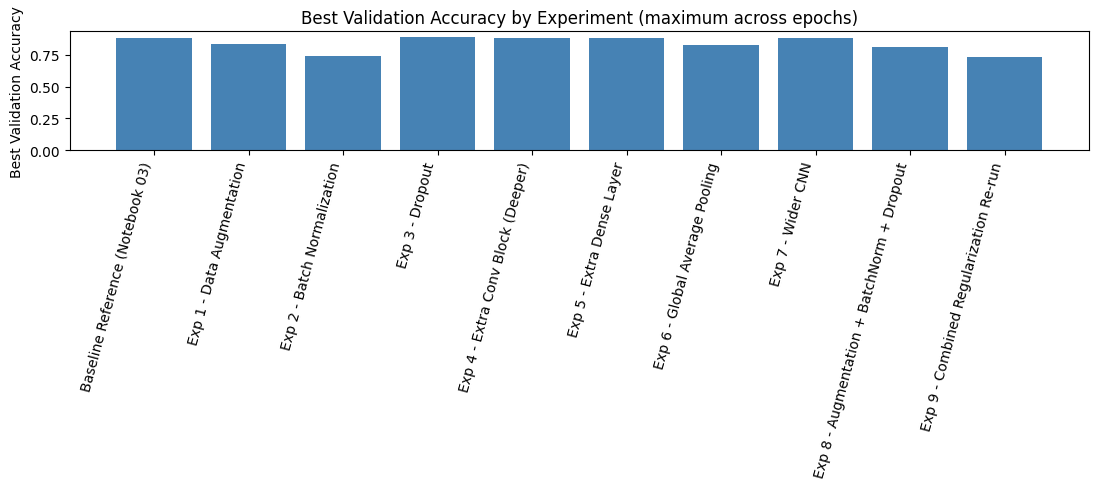

In [16]:
plt.figure(figsize=(11, 5))
plt.bar(results_df["Experiment"], results_df["Best Val Accuracy"], color="steelblue")
plt.ylabel("Best Validation Accuracy")
plt.title("Best Validation Accuracy by Experiment (maximum across epochs)")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

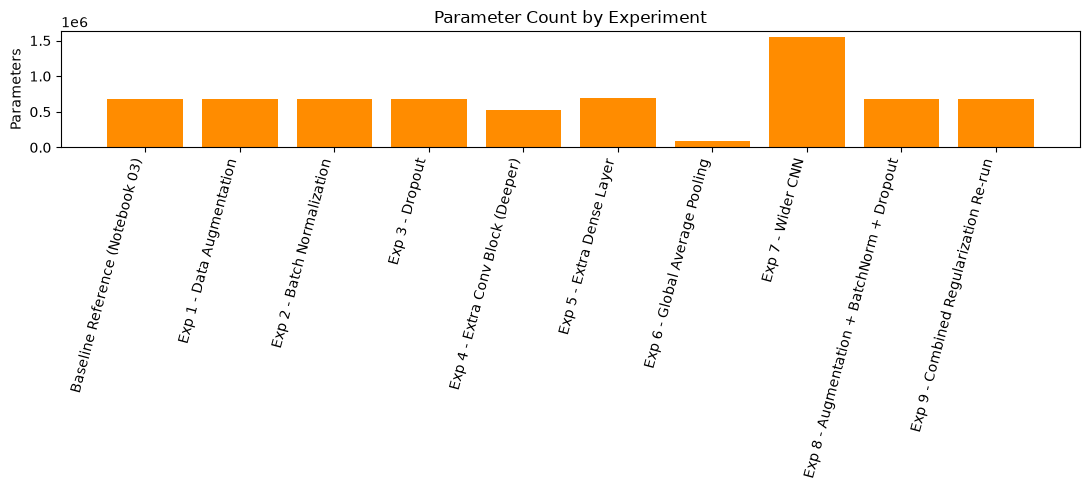

In [17]:
plt.figure(figsize=(11, 5))
plt.bar(results_df["Experiment"], results_df["Parameters"], color="darkorange")
plt.ylabel("Parameters")
plt.title("Parameter Count by Experiment")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

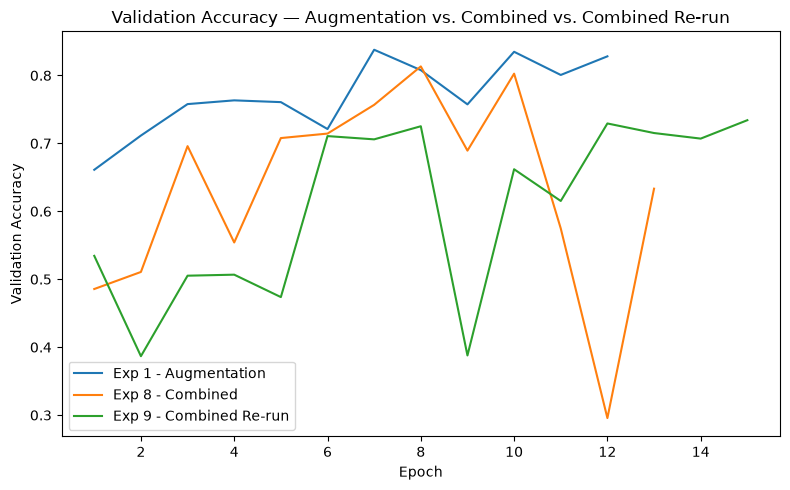

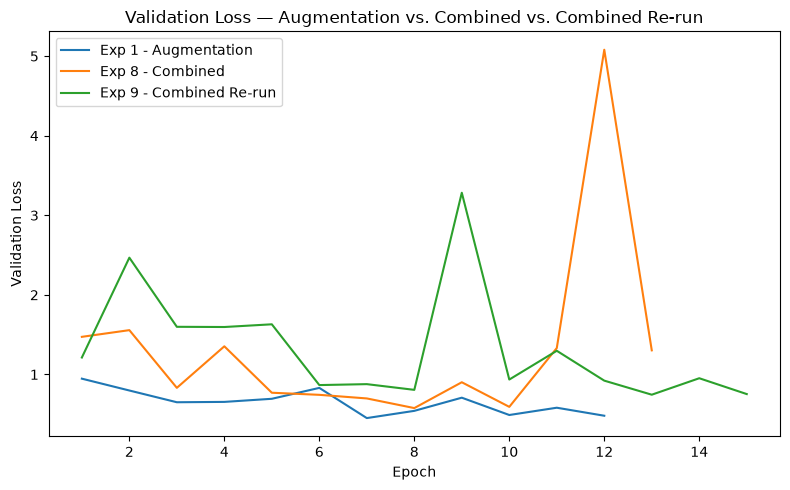

In [ ]:
# Curves use the per-epoch histories returned by compile_and_train for Experiments 1, 8 and 9
# (hist_aug, hist_combined, hist_exp9_rerun), so no values are re-typed here
plt.figure(figsize=(8, 5))
plt.plot(hist_aug.index, hist_aug["val_accuracy"], label="Exp 1 - Augmentation")
plt.plot(hist_combined.index, hist_combined["val_accuracy"], label="Exp 8 - Combined")
plt.plot(hist_exp9_rerun.index, hist_exp9_rerun["val_accuracy"], label="Exp 9 - Combined Re-run")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy — Augmentation vs. Combined vs. Combined Re-run")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(hist_aug.index, hist_aug["val_loss"], label="Exp 1 - Augmentation")
plt.plot(hist_combined.index, hist_combined["val_loss"], label="Exp 8 - Combined")
plt.plot(hist_exp9_rerun.index, hist_exp9_rerun["val_loss"], label="Exp 9 - Combined Re-run")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss — Augmentation vs Combined vs Combined Re-run")
plt.legend()
plt.tight_layout()
plt.show()

## 19. Analysis

**Baseline.** The baseline CNN reached 88.00% maximum validation accuracy (Epoch 10) and remains the reference point for every controlled change below. All numbers in this section are single-run validation results.

**Data Augmentation.** Experiment 1 reached 83.78% maximum validation accuracy — lower than the baseline in this run. That doesn't support a general claim that augmentation is harmful; it means the specific augmentation settings used here (`RandomFlip`, `RandomRotation(0.1)`, `RandomZoom(0.1)`) did not improve validation performance in this particular experiment.

**Batch Normalization.** Experiment 2 reached 73.93% maximum validation accuracy (Epoch 6), with its minimum validation loss, 0.8036, at Epoch 3. As with augmentation, this doesn't show that Batch Normalization is generally bad — this specific implementation and run did not improve on the baseline here.

**Dropout.** Experiment 3 achieved the highest maximum validation accuracy recorded among the CNN experiments in this notebook (88.96% at Epoch 15), with a minimum validation loss of 0.3327 (Epoch 12) — lower than the baseline's 0.3607. Its maximum-accuracy epoch (15) is different from its best-loss epoch (12): the two metrics don't have to move together. Because `EarlyStopping` monitored validation loss, the restored weights correspond to the best validation-loss epoch (Epoch 12), where validation accuracy was 88.59%, so 88.96% is not the accuracy of the restored model. Because the best accuracy occurred at the last allowed epoch, this run does not show whether further training would have helped or hurt.

**Deeper CNN.** Experiment 4 reached 88.07%, very close to the baseline. Despite adding a fourth conv block, its parameter count (520,906) is actually *lower* than the baseline's 684,490 — the extra pooling operation shrinks the spatial dimensions further before `Flatten`, so the flattened feature vector (and the large dense-layer weight matrix that follows it) ends up smaller, not larger.

**Extra Dense Layer.** Experiment 5 reached 88.41%, close to the baseline, but the later training epochs show a widening gap between training and validation performance (training accuracy ≈ 96.34% vs. validation accuracy ≈ 86.07% by Epoch 15) — a sign of overfitting from the added classifier capacity, even though the best validation-epoch number itself looks fine.

**Global Average Pooling.** Experiment 6 cut parameters drastically, from 684,490 to 94,538, and its validation accuracy was lower, at 82.85%. This is the parameter-efficiency/representational-capacity trade-off in practice within a 15-epoch budget. Its training and validation metrics were both still improving at Epoch 15, so the result reflects this model after 15 epochs and is not necessarily its best achievable performance.

**Wider CNN.** Experiment 7 reached a maximum validation accuracy of 88.04% — about level with the baseline — while using 1,551,882 parameters (over 2× the baseline) and 1,967.4 seconds (about 32.8 minutes) of training time, the longest of the experiments. The extra width did not produce a meaningful validation-accuracy improvement here relative to its added cost.

**Combined Augmentation + BatchNorm + Dropout.** Experiment 8 reached 81.33% with visibly unstable validation behavior across epochs. Experiment 9, run separately on the *same* architecture, reached only 73.41% maximum validation accuracy, with even sharper swings in the per-epoch log (validation accuracy briefly collapsing to 38.78% at Epoch 9, and validation loss spiking to 3.28 at that epoch). The difference between the two runs is consistent with run-to-run variability. This may reflect stochastic effects from training and augmentation, but this notebook does not isolate the specific cause, and neither number alone should be treated as the result for this architecture.

**Epoch-cap caveat.** All experiments were capped at 15 epochs. Experiments 3 (Dropout), 6 (Global Average Pooling), and 9 (combined re-run) recorded their best validation accuracy at Epoch 15, and Experiment 5 ran all 15 epochs without triggering `EarlyStopping`. For these runs the comparison with the baseline (which `EarlyStopping` stopped at Epoch 15 in Notebook 03) is a comparison at the same epoch budget; it is not evidence that more epochs would not have changed the picture.

Overall, among the experiments in this notebook, Dropout (Experiment 3) had the highest maximum recorded validation accuracy (and the lowest minimum validation loss), and the Deeper CNN (Experiment 4) recorded essentially the same accuracy as the baseline at a lower parameter count. Differences of well under one percentage point (about 27 validation images per point) should not be over-interpreted from single runs. No technique here is being judged as universally better or worse — these conclusions are scoped strictly to this dataset, this baseline, and these specific runs. The test set was not used for any of this analysis.


## 20. Key Observations

1. The baseline provides a reference point at 88.00% validation accuracy (minimum validation loss 0.3607).
2. Dropout had the highest maximum recorded validation accuracy among these experiments, 88.96% at Epoch 15 (0.96 points above the baseline, from a single run). Its restored weights correspond to the best validation-loss epoch (Epoch 12), where validation accuracy was 88.59%.
3. The epoch with the best validation loss does not always match the epoch with the highest validation accuracy (Experiment 2: accuracy best at Epoch 6, loss best at Epoch 3; Experiment 3: loss best at Epoch 12, accuracy best at Epoch 15) — `EarlyStopping` monitors validation loss, so the restored weights follow the best-*loss* epoch rather than the maximum-accuracy epoch; this is a reason to check both numbers rather than assume they coincide.
4. Increasing depth (Experiment 4) or width (Experiment 7) did not produce a meaningful validation-accuracy gain over the baseline in these runs, though the deeper variant did so with fewer parameters.
5. Global Average Pooling (Experiment 6) greatly reduced parameter count (684,490 → 94,538) and had lower validation accuracy (88.00% → 82.85%) within the 15-epoch cap; its metrics were still improving at Epoch 15, so the trade-off is measured at that budget.
6. The extra dense layer (Experiment 5) showed signs of overfitting in its later epochs, despite a reasonable best-epoch validation accuracy.
7. Two separate runs of the *same* combined augmentation/BatchNorm/Dropout architecture (Experiments 8 and 9) gave substantially different results (81.33% vs. 73.41%), consistent with run-to-run variability; this notebook does not isolate the cause.
8. Experiments 3, 6, and 9 reached their best recorded validation accuracy at the last allowed epoch (15), so those results are bounded by the epoch cap.
9. The test set was not used for any of these decisions or comparisons — it remains reserved for Notebook 08.

None of these observations should be read as a universal claim about any technique; they describe what happened on this dataset, with this baseline, in these specific runs.
